<a href="https://colab.research.google.com/github/internallocus01/COU07506-Labs/blob/main/COU07506__Week01_240242454460.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

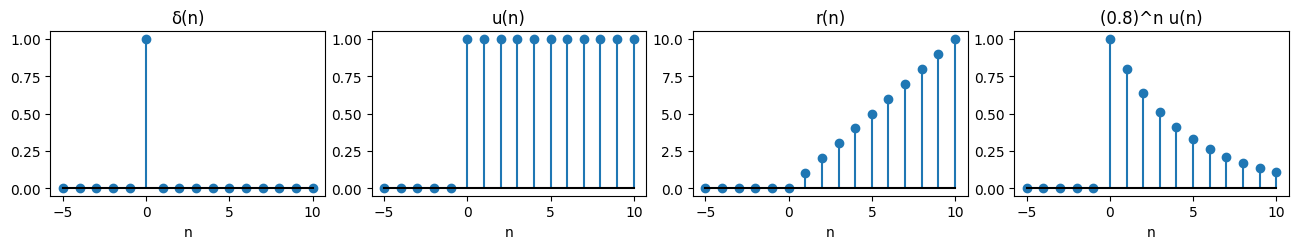

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step  = (n >= 0).astype(float)
ramp  = n * step
expo  = 0.8**n * step

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

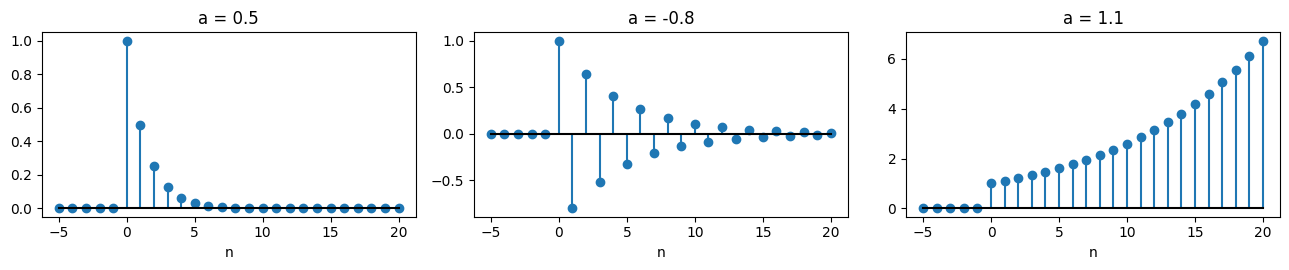

In [9]:
n = np.arange(-5, 21)
u = (n >= 0).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, (a**n.astype(float)) * u, basefmt="k-")
    ax.set_title(f"a = {a}"); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

In [10]:
!pip -q install pydub
from pydub import AudioSegment
AudioSegment.from_file("sound_recording.aac").export("my_voice.wav", format="wav")

<_io.BufferedRandom name='my_voice.wav'>

fs = 44100 Hz, duration = 5.02 s, samples = 221184


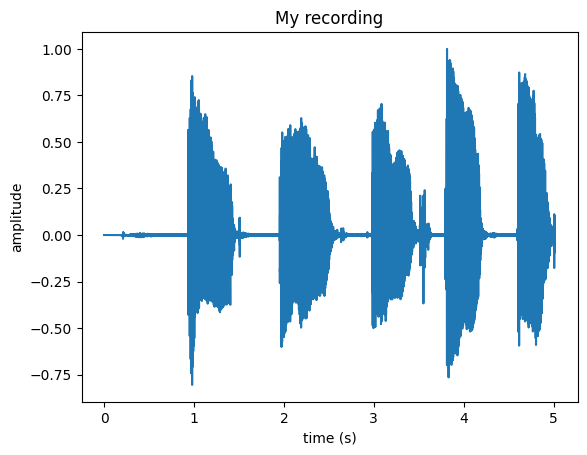

In [11]:
import os
fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))
else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

In [12]:
from IPython.display import Audio
Audio(x, rate=fs)

1.My recording's sampling rate is fs = 44,000Hz. One minute in mono needs 60 × 44,000 = 2,646,000. (At 44,100 Hz that is 2,646,000.)

2.x(n) is a discrete-time signal defined only at integer n, so a stem plot shows each sample separately. A continuous line would wrongly imply values between samples.

3.For a = 1.1 the sequence grows without bound, so Σ|h(n)| = ∞. Such a system would violate BIBO stability, because a bounded input could give an unbounded output.

https://github.com/internallocus01/COU07506-Labs.git